In [1]:
import sys
print(sys.executable)

C:\Users\Administrator\Documents\CMU\financial_data_analysis_1\.venv\Scripts\python.exe


In [2]:
import yfinance as yf
import pandas as pd
import statsmodels.api as sm
import numpy as np
import matplotlib.pyplot as plt

In [3]:
target = "JPM"
hedge = "BAC"

prices = yf.download([target, hedge], start="2025-01-01", end="2026-01-01")["Close"]

prices = prices.dropna()

returns = prices.pct_change().dropna()


[*********************100%***********************]  2 of 2 completed

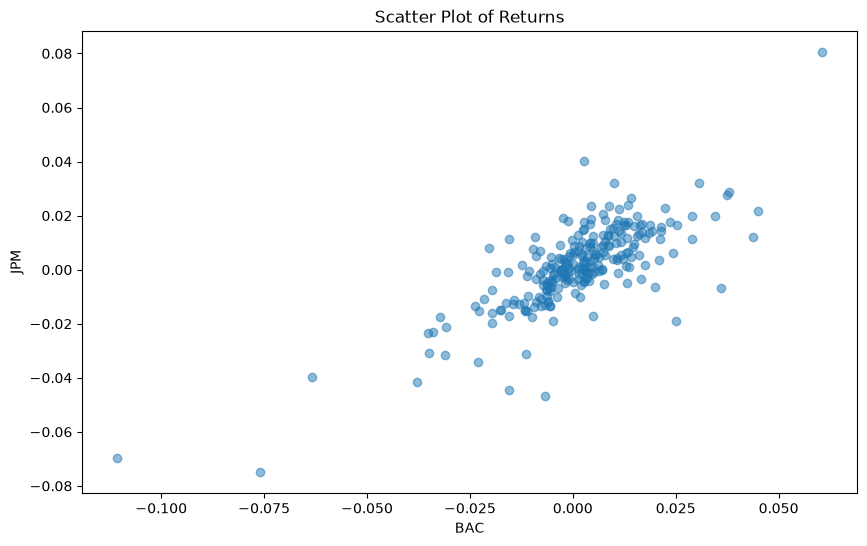

In [4]:
RY=returns[target]
RX=returns[hedge]

plt.figure(figsize=(10, 6))
plt.scatter(RX, RY, alpha=0.5)
plt.xlabel(hedge)
plt.ylabel(target)
plt.title("Scatter Plot of Returns")
plt.show()


In [5]:
X=sm.add_constant(RX)  # Add a constant term for the intercept
model = sm.OLS(RY, X).fit()  # Fit the OLS model

In [6]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                    JPM   R-squared:                       0.607
Model:                            OLS   Adj. R-squared:                  0.606
Method:                 Least Squares   F-statistic:                     381.9
Date:                Sat, 05 Sep 2026   Prob (F-statistic):           4.89e-52
Time:                        15:26:23   Log-Likelihood:                 798.13
No. Observations:                 249   AIC:                            -1592.
Df Residuals:                     247   BIC:                            -1585.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0006      0.001      0.942      0.3

In [7]:
hedge_ratio = model.params[hedge]
print(f"Hedge Ratio (Beta): {hedge_ratio}")

Hedge Ratio (Beta): 0.724999976228322


In [8]:
CI = model.conf_int(alpha=0.05).loc[hedge]
print(f"95% Confidence Interval for Hedge Ratio: {CI.values}")

95% Confidence Interval for Hedge Ratio: [0.65192515 0.79807481]


In [9]:
hedged_returns = RY - hedge_ratio * RX

target_variance = RY.var()
hedged_variance = hedged_returns.var()
print(f"Variance of {target} Returns: {target_variance}")
print(f"Variance of Hedged Returns: {hedged_variance}")

elimation_ratio = (target_variance - hedged_variance) / target_variance
print(f"Variance Elimination Ratio: {elimation_ratio * 100:.2f}%")

Variance of JPM Returns: 0.0002460374559122898
Variance of Hedged Returns: 9.663733637824308e-05
Variance Elimination Ratio: 60.72%


In [10]:
correlation = RY.corr(RX)
print(f"Correlation between {target} and {hedge} Returns: {correlation}")

Correlation between JPM and BAC Returns: 0.7792464970117344
